# Módulo 2 · 01 · Datos y partición sin fuga

Conjunto: *Multi-Class Driver Behavior Image Dataset* (Afridi et al., 2024), Mendeley Data,
[DOI 10.17632/mzb4b6dff3.1](https://doi.org/10.17632/mzb4b6dff3.1), licencia CC BY 4.0.

Salidas versionadas en `data/processed/`: `imagenes/` (224×168), `metadatos.csv`, `particion.csv`,
`caracteristicas_resnet18.npy`. El zip original (2,5 GB) no se versiona: se baja con `FORZAR=True`.

In [1]:
# parameters
DEMO = False
FORZAR = False   # vuelve a bajar y procesar las imágenes

In [2]:
import sys
from pathlib import Path
RAIZ = Path.cwd().resolve().parents[1]
sys.path[:0] = [str(RAIZ), str(RAIZ / "modulo2_distraccion")]

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common.seeds import fijar_semilla
import m2lib, m2exp

fijar_semilla()
cfg = m2exp.config(demo=DEMO)
CLASES = cfg["datos"]["clases"]
ETIQ = [m2lib.NOMBRES[c] for c in CLASES]
FIG, RES = m2lib.FIGURAS, m2lib.RESULTADOS
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

## 1. Descarga y procesamiento

Se verifica el sha256 del zip. Cada imagen se reduce a 224×168 (4:3, como el 91 % del conjunto) sin deformarla, rellenando con gris; se guardan su tamaño original, el sha1 de los bytes y un hash perceptual (dHash de 64 bits).

In [3]:
if FORZAR or not (m2lib.PROC / "metadatos.csv").exists():
    m2lib.descargar(cfg)
    m2lib.preparar(cfg)
meta_todo = m2lib.cargar_metadatos()
print(len(meta_todo), "archivos;", int(meta_todo["corrupta"].sum()), "corruptos (llenos de ceros)")
meta_todo[meta_todo["corrupta"]][["clase", "original", "bytes"]]

7286 archivos; 10 corruptos (llenos de ceros)


,clase,original,bytes
1775,turning,img_101434.jpg,49581
2269,turning,img_62337.jpg,51288
2360,turning,img_67523.jpg,45275
2419,turning,img_70552.jpg,40563
6207,other_activities,img_13318.jpg,41375
6212,other_activities,img_13396.jpg,43719
6229,other_activities,img_13541.jpg,39889
6236,other_activities,img_13625.jpg,41815
6925,other_activities,img_20398.jpg,40099
7066,other_activities,img_22266.jpg,43061


In [4]:
meta = m2lib.origen_statefarm(m2lib.validas())
tabla = meta.groupby("clase").size().rename("imagenes").to_frame()
tabla["porcentaje"] = (100 * tabla["imagenes"] / tabla["imagenes"].sum()).round(1)
tabla.loc[CLASES]

,imagenes,porcentaje
clase,,
safe_driving,1679,23.1
turning,1339,18.4
texting_phone,1561,21.5
talking_phone,1513,20.8
other_activities,1184,16.3


## 2. Resolución y origen de las imágenes

In [5]:
res = meta.groupby(["ancho_original", "alto_original"]).size().sort_values(ascending=False).rename("imagenes")
res.to_frame()

,,imagenes
ancho_original,alto_original,
640.0,480.0,6629
683.0,384.0,183
3072.0,4096.0,182
2460.0,3280.0,135
4096.0,3072.0,80
4032.0,3024.0,32
720.0,1280.0,8
576.0,720.0,1
611.0,964.0,1


El artículo dice que todas las imágenes miden 400×600 y que se tomaron en Dhaka en octubre de 2024 con dos celulares.
Ninguna mide 400×600, y el 91 % mide 640×480 con nombres `img_NNNNN.jpg`, el formato del concurso
*State Farm Distracted Driver Detection* (Kaggle, 2016). Se cruzan los nombres con su `driver_imgs_list.csv`
(26 conductores, 10 clases c0–c9):

In [6]:
cruce = pd.crosstab(meta["clase"], meta["clase_statefarm"].fillna("no State Farm")).loc[CLASES]
cruce.columns = [f"{c} {m2lib.CLASES_STATEFARM.get(c, '')}".strip() for c in cruce.columns]
cruce.to_csv(RES / "origen_statefarm.csv")
print(f"De State Farm: {meta['conductor'].notna().sum()} de {len(meta)} ({100*meta['conductor'].notna().mean():.1f} %)")
cruce.T

De State Farm: 6629 de 7276 (91.1 %)


clase,safe_driving,turning,texting_phone,talking_phone,other_activities
c0 conducción segura,1531,0,0,0,0
c1 escribir (mano derecha),0,0,751,0,0
c2 hablar (mano derecha),0,0,0,743,0
c3 escribir (mano izquierda),0,0,754,0,0
c4 hablar (mano izquierda),0,0,0,691,0
c5 manipular el radio,0,0,0,0,211
c6 beber,0,0,0,0,195
c7 alcanzar algo atrás,0,1187,0,0,0
c8 peinarse o maquillarse,0,0,0,0,275
c9 hablar con el pasajero,0,0,0,0,291


Cada clase del conjunto corresponde exactamente a clases de State Farm. Dos consecuencias:

* **«turning» (giro) mezcla dos comportamientos**: sus 1 191 imágenes de State Farm son la clase c7, «alcanzar algo atrás» (el conductor se voltea hacia el asiento trasero), mientras que las 152 de otro origen sí muestran a alguien girando el volante (figura de ejemplos, abajo).
* La mayoría de las imágenes son de 26 conductores en Estados Unidos, en el mismo carro y con la misma cámara fija, no de buses en Bangladesh.

## 3. Grupos de imágenes casi iguales

State Farm extrajo cuadros de video: cada imagen tiene casi siempre una gemela del mismo conductor. Si una cae en entrenamiento y la otra en prueba, el modelo se evalúa sobre algo que ya vio. Se mide la similitud con el coseno entre características de ResNet18 preentrenada (congelada) y con la distancia de Hamming del dHash.

mismo conductor, mediana 0.98 | otro conductor, máximo 0.952


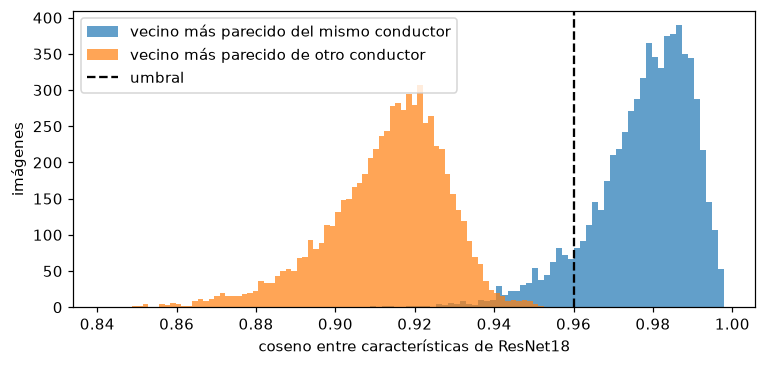

In [7]:
if FORZAR or not (m2lib.PROC / "caracteristicas_resnet18.npy").exists():
    np.save(m2lib.PROC / "caracteristicas_resnet18.npy", m2lib.caracteristicas(meta).astype(np.float16))
F = m2lib.cargar_caracteristicas()
f = F / np.linalg.norm(F, axis=1, keepdims=True)
S = f @ f.T; np.fill_diagonal(S, -1)
c = np.asarray(meta["conductor"].fillna("-").astype(str), dtype=object)
mismo = c[:, None] == c[None, :]
sf = meta["conductor"].notna().to_numpy()
v_mismo = np.where(mismo, S, -1)[sf].max(1)
v_otro = np.where(~mismo, S, -1)[sf].max(1)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(v_mismo, bins=80, alpha=.7, label="vecino más parecido del mismo conductor")
ax.hist(v_otro, bins=80, alpha=.7, label="vecino más parecido de otro conductor")
ax.axvline(cfg["particion"]["umbral_similitud"], color="k", ls="--", label="umbral")
ax.set_xlabel("coseno entre características de ResNet18"); ax.set_ylabel("imágenes"); ax.legend()
fig.savefig(FIG / "similitud_vecinos.png")
print("mismo conductor, mediana", np.median(v_mismo).round(3), "| otro conductor, máximo", v_otro.max().round(3))

El umbral 0,96 queda por encima de la similitud máxima entre conductores distintos y por debajo de la típica dentro del mismo conductor.

## 4. Partición

Grupo = conductor de State Farm, unido con cualquier par casi igual (coseno ≥ 0,96 o dHash a ≤ 4 bits) de todo el conjunto, por componentes conexas. Luego `StratifiedGroupKFold`: un grupo completo cae en una sola partición y la proporción de clases se mantiene.

In [8]:
P = cfg["particion"]
grupos, pares = m2lib.grupos_particion(meta, F, P["umbral_similitud"], P["umbral_hash"])
meta["grupo"] = grupos
meta["particion"] = m2lib.particionar(meta, grupos, P["fraccion_validacion"], P["fraccion_prueba"])
if not DEMO:
    m2lib.guardar_particion(meta)
print(len(np.unique(grupos)), "grupos;", pares)
print({p: sorted(meta.loc[meta.particion == p, "conductor"].dropna().unique()) for p in ["validacion", "prueba"]})
pd.crosstab(meta["clase"], meta["particion"], margins=True).loc[CLASES + ["All"], ["entrenamiento", "validacion", "prueba", "All"]]

392 grupos; {'hash': 44567, 'coseno': 43523}
{'validacion': ['p002', 'p012', 'p015', 'p016'], 'prueba': ['p042', 'p047', 'p051', 'p056']}


particion,entrenamiento,validacion,prueba,All
clase,,,,
safe_driving,1182,236,261,1679
turning,961,189,189,1339
texting_phone,1113,231,217,1561
talking_phone,1058,245,210,1513
other_activities,846,169,169,1184
All,5160,1070,1046,7276


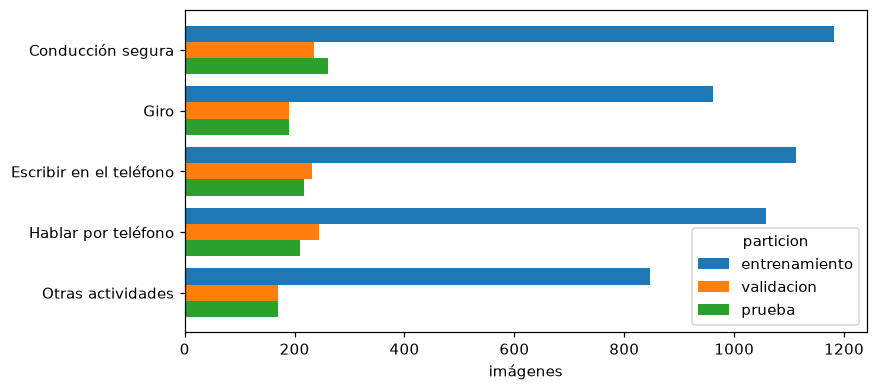

In [9]:
orden = ["entrenamiento", "validacion", "prueba"]
t = pd.crosstab(meta["clase"], meta["particion"]).loc[CLASES, orden]
ax = t.set_index(pd.Index(ETIQ)).plot.barh(figsize=(8, 3.8), width=.8)
ax.set_xlabel("imágenes"); ax.set_ylabel(""); ax.invert_yaxis()
plt.savefig(FIG / "imagenes_por_clase_particion.png")

## 5. Verificación de que no hay fuga

Para cada par de particiones se cuentan los pares de imágenes casi iguales (deben ser 0) y la similitud máxima entre ellas.

In [10]:
fuga = m2lib.verificar_fuga(meta, F, P["umbral_similitud"], P["umbral_hash"])
fuga.to_csv(RES / "verificacion_fuga.csv", index=False)
fuga

,particiones,pares_coseno,pares_hash,coseno_maximo,hamming_minimo,coseno_vecino_mediana
0,entrenamiento / validacion,0,0,0.9589,5,0.9058
1,entrenamiento / prueba,0,0,0.9597,5,0.9089
2,validacion / prueba,0,0,0.9526,6,0.8846


## 6. Ejemplos por clase

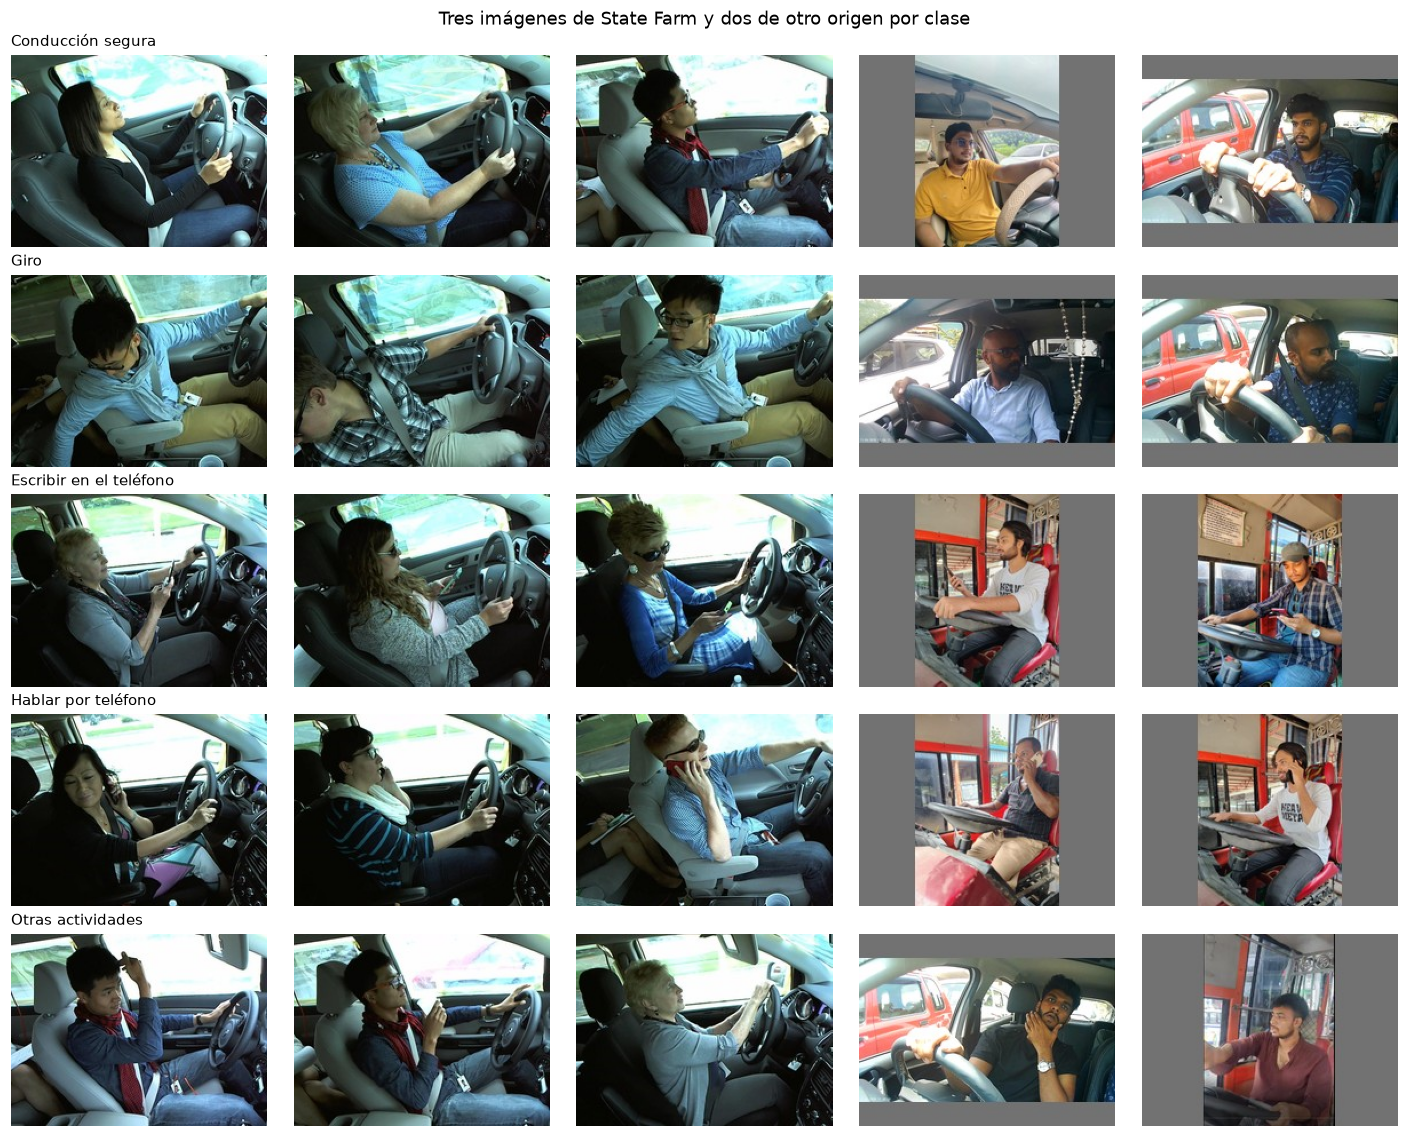

In [11]:
from PIL import Image
fig, axs = plt.subplots(len(CLASES), 5, figsize=(13, 2.1 * len(CLASES)))
rng = np.random.default_rng(3)
for i, cl in enumerate(CLASES):
    d = meta[meta.clase == cl]
    elegidas = list(d[d.conductor.notna()].sample(3, random_state=i).archivo) + list(d[d.conductor.isna()].sample(2, random_state=i).archivo)
    for j, a in enumerate(elegidas):
        axs[i, j].imshow(Image.open(m2lib.PROC / "imagenes" / a)); axs[i, j].axis("off")
    axs[i, 0].set_title(m2lib.NOMBRES[cl], loc="left", fontsize=10)
fig.suptitle("Tres imágenes de State Farm y dos de otro origen por clase")
fig.tight_layout()
fig.savefig(FIG / "ejemplos_por_clase.png")